<a href="https://colab.research.google.com/github/RajalakshmiTharmaraj/ProjectNew/blob/main/Raw%20to%20processed%20data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q pandas openpyxl

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries loaded successfully")

Libraries loaded successfully


In [6]:
from google.colab import files

uploaded = files.upload()


Saving Thoothukudi_ML_Required_Dataset_2015_2025_v11_Reservoir_Monthly_Proxy_Filled (1).xlsx to Thoothukudi_ML_Required_Dataset_2015_2025_v11_Reservoir_Monthly_Proxy_Filled (1).xlsx


In [7]:
file_path = list(uploaded.keys())[0]

print("Uploaded file:", file_path)

Uploaded file: Thoothukudi_ML_Required_Dataset_2015_2025_v11_Reservoir_Monthly_Proxy_Filled (1).xlsx


In [8]:
excel_file = pd.ExcelFile(file_path)

print("Available sheets:")
for sheet in excel_file.sheet_names:
    print("-", sheet)

Available sheets:
- Climate_2015_2025
- Groundwater_2015_2025
- Reservoirs_2015_2025
- Agriculture_Annual_Features
- Sector_Water_Components
- RAW_DATA_REVIEW_READY
- FINAL_DATA_READINESS
- FINALISATION_NOTE
- ML_DATASET_INDEX
- Monthly_Integrated_2015_2025


In [9]:
climate = pd.read_excel(
    file_path,
    sheet_name="Climate_2015_2025"
)

groundwater = pd.read_excel(
    file_path,
    sheet_name="Groundwater_2015_2025"
)

reservoir = pd.read_excel(
    file_path,
    sheet_name="Reservoirs_2015_2025"
)

agriculture = pd.read_excel(
    file_path,
    sheet_name="Agriculture_Annual_Features"
)

sector = pd.read_excel(
    file_path,
    sheet_name="Sector_Water_Components"
)

monthly = pd.read_excel(
    file_path,
    sheet_name="Monthly_Integrated_2015_2025"
)

print("Climate:", climate.shape)
print("Groundwater:", groundwater.shape)
print("Reservoir:", reservoir.shape)
print("Agriculture:", agriculture.shape)
print("Sector:", sector.shape)
print("Monthly Integrated:", monthly.shape)

Climate: (132, 15)
Groundwater: (104, 12)
Reservoir: (28, 11)
Agriculture: (10, 16)
Sector: (21, 8)
Monthly Integrated: (132, 25)


In [10]:
monthly.head(12)

,Date,Year,Month,Season,Rainfall_mm,Max_Temp_C,Min_Temp_C,Avg_Temp_C,Avg_Humidity_pct,GW_Monthly_Avg_Level_m_bgl,...,Annual_Selected_Crop_Area_Total_ha_Context,Annual_Agriculture_GW_Extraction_ML_Context,Annual_Industrial_GW_Extraction_ML_Context,Annual_Domestic_GW_Extraction_ML_Context,Annual_Context_Year,Monthly_Data_Status,Missing_Monthly_Fields,Notes,Reservoir_Value_Type,Reservoir_Proxy_Method
0,2015-01-01,2015,January,Winter,1.2,30.2,23.1,26.65,79.5,6.2725,...,135522.0,180452.0,3654.0,4398.0,2015,Monthly climate available; reservoir value is ...,Reservoir,Reservoir storage/inflow/outflow are temporal ...,Estimated Proxy,Temporal interpolation between nearest observe...
1,2015-02-01,2015,February,Winter,2.2,31.0,23.4,27.20,76.5,NaN,...,135522.0,180452.0,3654.0,4398.0,2015,Monthly climate available; reservoir value is ...,"Groundwater, Reservoir",Reservoir storage/inflow/outflow are temporal ...,Estimated Proxy,Temporal interpolation between nearest observe...
2,2015-03-01,2015,March,Hot Weather,11.4,32.5,25.0,28.75,76.5,NaN,...,135522.0,180452.0,3654.0,4398.0,2015,Monthly climate available; reservoir value is ...,"Groundwater, Reservoir",Reservoir storage/inflow/outflow are temporal ...,Estimated Proxy,Temporal interpolation between nearest observe...
3,2015-04-01,2015,April,Hot Weather,24.6,34.1,26.2,30.15,74.5,NaN,...,135522.0,180452.0,3654.0,4398.0,2015,Monthly climate available; reservoir value is ...,"Groundwater, Reservoir",Reservoir storage/inflow/outflow are temporal ...,Estimated Proxy,Temporal interpolation between nearest observe...
4,2015-05-01,2015,May,Hot Weather,13.5,36.4,27.5,31.95,71.0,7.6050,...,135522.0,180452.0,3654.0,4398.0,2015,Monthly climate available; reservoir value is ...,Reservoir,Reservoir storage/inflow/outflow are temporal ...,Estimated Proxy,Temporal interpolation between nearest observe...
5,2015-06-01,2015,June,South West Monsoon,8.5,37.1,27.2,32.15,66.5,NaN,...,135522.0,180452.0,3654.0,4398.0,2015,Monthly climate available; reservoir value is ...,"Groundwater, Reservoir",Reservoir storage/inflow/outflow are temporal ...,Estimated Proxy,Temporal interpolation between nearest observe...
6,2015-07-01,2015,July,South West Monsoon,12.4,36.2,26.8,31.50,69.0,NaN,...,135522.0,180452.0,3654.0,4398.0,2015,Monthly climate available; reservoir value is ...,"Groundwater, Reservoir",Reservoir storage/inflow/outflow are temporal ...,Estimated Proxy,Temporal interpolation between nearest observe...
7,2015-08-01,2015,August,South West Monsoon,18.6,35.8,26.5,31.15,69.0,7.9825,...,135522.0,180452.0,3654.0,4398.0,2015,Monthly climate available; reservoir value is ...,Reservoir,Reservoir storage/inflow/outflow are temporal ...,Estimated Proxy,Temporal interpolation between nearest observe...
8,2015-09-01,2015,September,South West Monsoon,20.5,36.0,26.4,31.20,69.0,NaN,...,135522.0,180452.0,3654.0,4398.0,2015,Monthly climate available; reservoir value is ...,"Groundwater, Reservoir",Reservoir storage/inflow/outflow are temporal ...,Estimated Proxy,Temporal interpolation between nearest observe...
9,2015-10-01,2015,October,North East Monsoon,218.4,32.8,25.1,28.95,77.5,NaN,...,135522.0,180452.0,3654.0,4398.0,2015,Monthly climate available; reservoir value is ...,"Groundwater, Reservoir",Reservoir storage/inflow/outflow are temporal ...,Estimated Proxy,Temporal interpolation between nearest observe...


In [11]:
for col in monthly.columns:
    print(col)

Date
Year
Month
Season
Rainfall_mm
Max_Temp_C
Min_Temp_C
Avg_Temp_C
Avg_Humidity_pct
GW_Monthly_Avg_Level_m_bgl
GW_Observation_Count
Reservoir_Monthly_Avg_Storage_pct
Reservoir_Monthly_Avg_Inflow_Cusecs
Reservoir_Monthly_Avg_Outflow_Cusecs
Reservoir_Observation_Count
Annual_Selected_Crop_Area_Total_ha_Context
Annual_Agriculture_GW_Extraction_ML_Context
Annual_Industrial_GW_Extraction_ML_Context
Annual_Domestic_GW_Extraction_ML_Context
Annual_Context_Year
Monthly_Data_Status
Missing_Monthly_Fields
Notes
Reservoir_Value_Type
Reservoir_Proxy_Method


In [12]:
missing = pd.DataFrame({
    "Missing_Count": monthly.isnull().sum(),
    "Missing_Percentage":
        (monthly.isnull().sum() / len(monthly)) * 100
})

missing = missing.sort_values(
    "Missing_Percentage",
    ascending=False
)

missing

,Missing_Count,Missing_Percentage
GW_Monthly_Avg_Level_m_bgl,92,69.696970
Annual_Agriculture_GW_Extraction_ML_Context,60,45.454545
Annual_Domestic_GW_Extraction_ML_Context,48,36.363636
Annual_Industrial_GW_Extraction_ML_Context,48,36.363636
Annual_Selected_Crop_Area_Total_ha_Context,12,9.090909
Missing_Monthly_Fields,6,4.545455
Reservoir_Monthly_Avg_Outflow_Cusecs,2,1.515152
Reservoir_Monthly_Avg_Inflow_Cusecs,2,1.515152
Date,0,0.000000
Avg_Humidity_pct,0,0.000000


In [13]:
groundwater["Observation_Date"] = pd.to_datetime(
    groundwater["Observation_Date"]
)

groundwater["Year"] = groundwater["Observation_Date"].dt.year
groundwater["Month_No"] = groundwater["Observation_Date"].dt.month

gw_monthly = (
    groundwater
    .groupby(["Year", "Month_No"])
    .agg(
        GW_Monthly_Avg_Level_m_bgl=(
            "Groundwater_Level_m_bgl",
            "mean"
        ),
        GW_Observation_Count=(
            "Groundwater_Level_m_bgl",
            "count"
        )
    )
    .reset_index()
)

gw_monthly.head(20)

,Year,Month_No,GW_Monthly_Avg_Level_m_bgl,GW_Observation_Count
0,2015.0,1.0,6.272500,4
1,2015.0,5.0,7.605000,4
2,2015.0,8.0,7.982500,4
3,2015.0,11.0,2.980000,4
4,2016.0,1.0,3.786000,5
5,2016.0,5.0,8.970000,5
6,2016.0,8.0,9.790000,5
7,2016.0,11.0,9.480000,5
8,2017.0,1.0,9.050000,3
9,2017.0,5.0,10.466667,3


In [14]:
reservoir["Date"] = pd.to_datetime(reservoir["Date"])

reservoir["Year"] = reservoir["Date"].dt.year
reservoir["Month_No"] = reservoir["Date"].dt.month

reservoir_monthly = (
    reservoir
    .groupby(["Year", "Month_No"])
    .agg(
        Reservoir_Monthly_Avg_Storage_pct=(
            "Storage_pct",
            "mean"
        ),

        Reservoir_Monthly_Avg_Inflow_Cusecs=(
            "Inflow_Cusecs",
            "mean"
        ),

        Reservoir_Monthly_Avg_Outflow_Cusecs=(
            "Outflow_Cusecs",
            "mean"
        ),

        Reservoir_Observation_Count=(
            "Reservoir",
            "count"
        )
    )
    .reset_index()
)

reservoir_monthly

,Year,Month_No,Reservoir_Monthly_Avg_Storage_pct,Reservoir_Monthly_Avg_Inflow_Cusecs,Reservoir_Monthly_Avg_Outflow_Cusecs,Reservoir_Observation_Count
0,2015,12,95.360000,3032.5,2500.0,2
1,2016,8,16.070000,77.5,285.0,2
2,2017,11,40.330000,767.5,537.5,2
3,2018,1,39.510000,197.5,300.0,2
4,2019,11,72.065000,2002.5,877.5,2
5,2020,11,62.405000,1030.0,750.0,2
6,2021,11,85.560000,3250.0,1475.0,2
7,2022,11,37.785000,527.5,625.0,2
8,2023,12,99.675000,11700.0,9250.0,2
9,2024,7,48.070000,NaN,NaN,2


In [15]:
monthly[
    [
        "Date",
        "Reservoir_Monthly_Avg_Storage_pct",
        "Reservoir_Monthly_Avg_Inflow_Cusecs",
        "Reservoir_Monthly_Avg_Outflow_Cusecs",
        "Reservoir_Observation_Count",
        "Reservoir_Value_Type"
    ]
].head(20)

,Date,Reservoir_Monthly_Avg_Storage_pct,Reservoir_Monthly_Avg_Inflow_Cusecs,Reservoir_Monthly_Avg_Outflow_Cusecs,Reservoir_Observation_Count,Reservoir_Value_Type
0,2015-01-01,95.36000,3032.500,2500.000,0,Estimated Proxy
1,2015-02-01,95.36000,3032.500,2500.000,0,Estimated Proxy
2,2015-03-01,95.36000,3032.500,2500.000,0,Estimated Proxy
3,2015-04-01,95.36000,3032.500,2500.000,0,Estimated Proxy
4,2015-05-01,95.36000,3032.500,2500.000,0,Estimated Proxy
5,2015-06-01,95.36000,3032.500,2500.000,0,Estimated Proxy
6,2015-07-01,95.36000,3032.500,2500.000,0,Estimated Proxy
7,2015-08-01,95.36000,3032.500,2500.000,0,Estimated Proxy
8,2015-09-01,95.36000,3032.500,2500.000,0,Estimated Proxy
9,2015-10-01,95.36000,3032.500,2500.000,0,Estimated Proxy


In [16]:
monthly["Reservoir_Value_Type"].value_counts()

,count
Reservoir_Value_Type,
Estimated Proxy,120
Observed,12


In [17]:
monthly["Date"] = pd.to_datetime(monthly["Date"])

monthly = monthly.sort_values("Date").reset_index(drop=True)

monthly[["Date", "Year", "Month"]].head()

,Date,Year,Month
0,2015-01-01,2015,January
1,2015-02-01,2015,February
2,2015-03-01,2015,March
3,2015-04-01,2015,April
4,2015-05-01,2015,May


In [18]:
monthly["Rainfall_Lag_1"] = (
    monthly["Rainfall_mm"].shift(1)
)

In [19]:
monthly["Rainfall_3Month_Total"] = (
    monthly["Rainfall_mm"]
    .rolling(window=3)
    .sum()
)

In [21]:
monthly["Avg_Temp_Lag_1"] = (
    monthly["Avg_Temp_C"].shift(1)
)

In [23]:
monthly["Reservoir_Storage_Change_pct"] = (
    monthly[
        "Reservoir_Monthly_Avg_Storage_pct"
    ].diff()
)

In [24]:
monthly["GW_Observed_Flag"] = np.where(
    monthly["GW_Observation_Count"] > 0,
    1,
    0
)

In [25]:
monthly["Reservoir_Observed_Flag"] = np.where(
    monthly["Reservoir_Observation_Count"] > 0,
    1,
    0
)

In [26]:
monthly["Month_No"] = monthly["Date"].dt.month

monthly[
    ["Date", "Month", "Month_No"]
].head(12)

,Date,Month,Month_No
0,2015-01-01,January,1
1,2015-02-01,February,2
2,2015-03-01,March,3
3,2015-04-01,April,4
4,2015-05-01,May,5
5,2015-06-01,June,6
6,2015-07-01,July,7
7,2015-08-01,August,8
8,2015-09-01,September,9
9,2015-10-01,October,10


In [27]:
monthly["Month_Sin"] = np.sin(
    2 * np.pi * monthly["Month_No"] / 12
)

monthly["Month_Cos"] = np.cos(
    2 * np.pi * monthly["Month_No"] / 12
)

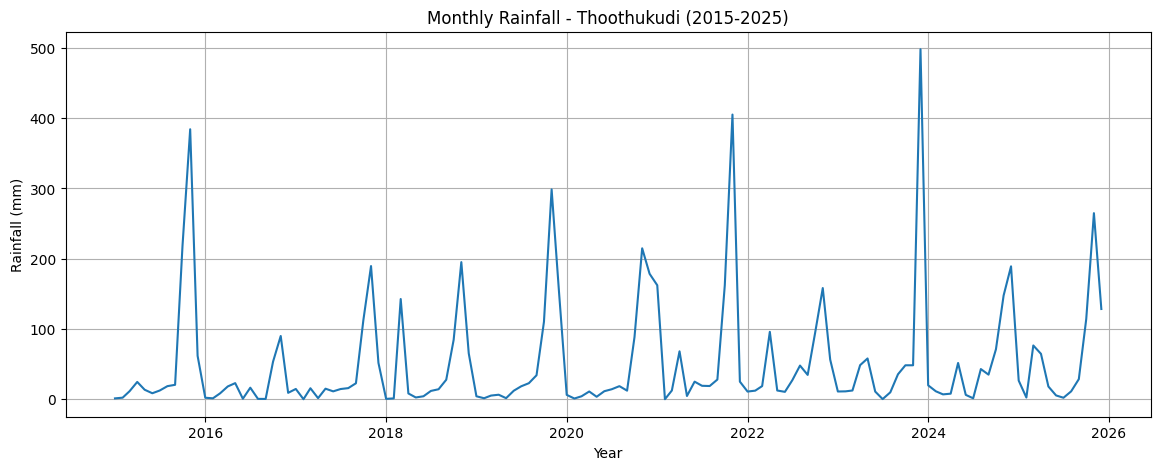

In [28]:
plt.figure(figsize=(14,5))

plt.plot(
    monthly["Date"],
    monthly["Rainfall_mm"]
)

plt.xlabel("Year")
plt.ylabel("Rainfall (mm)")
plt.title("Monthly Rainfall - Thoothukudi (2015-2025)")
plt.grid(True)

plt.show()

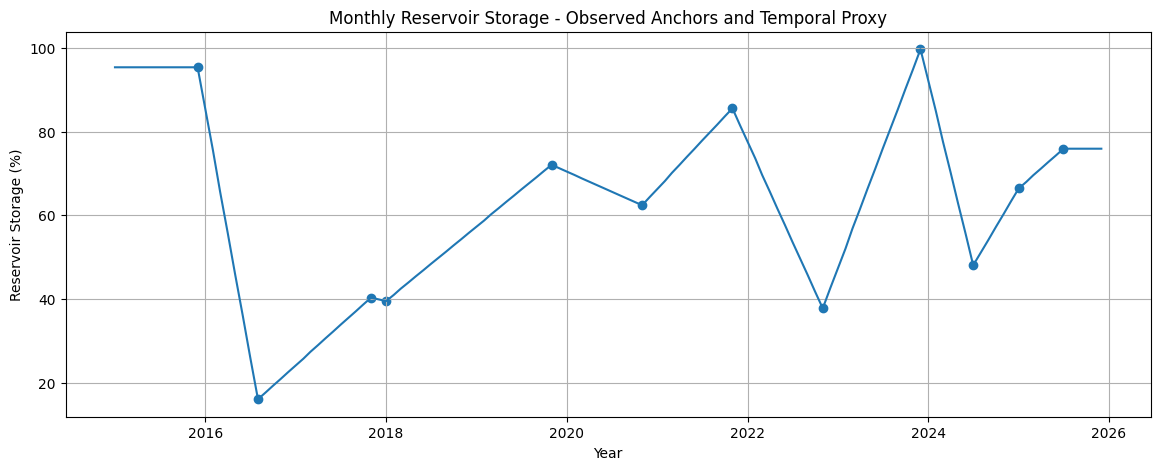

In [29]:
plt.figure(figsize=(14,5))

plt.plot(
    monthly["Date"],
    monthly["Reservoir_Monthly_Avg_Storage_pct"]
)

observed = monthly[
    monthly["Reservoir_Observation_Count"] > 0
]

plt.scatter(
    observed["Date"],
    observed["Reservoir_Monthly_Avg_Storage_pct"]
)

plt.xlabel("Year")
plt.ylabel("Reservoir Storage (%)")
plt.title(
    "Monthly Reservoir Storage - Observed Anchors and Temporal Proxy"
)

plt.grid(True)
plt.show()

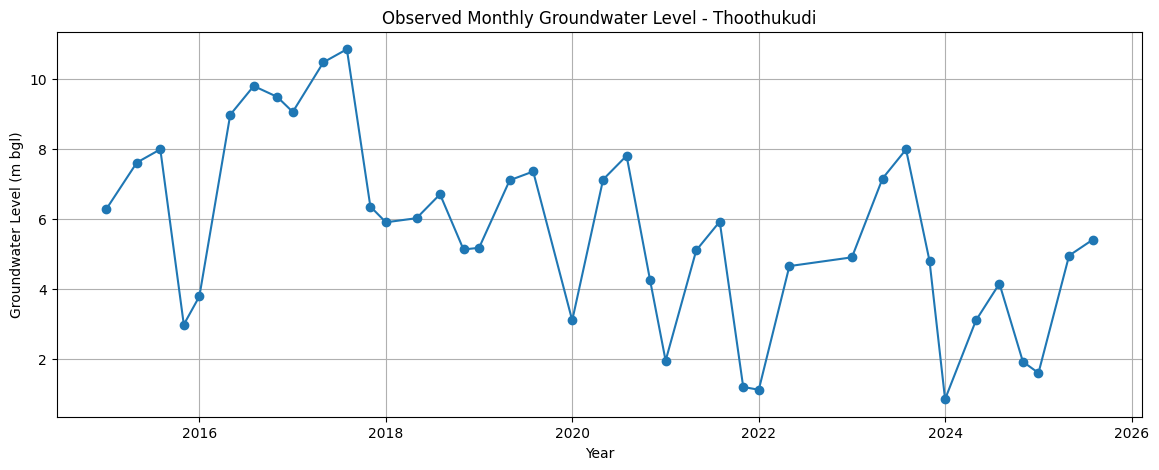

In [30]:
gw_observed = monthly[
    monthly["GW_Observation_Count"] > 0
]

plt.figure(figsize=(14,5))

plt.plot(
    gw_observed["Date"],
    gw_observed["GW_Monthly_Avg_Level_m_bgl"],
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Groundwater Level (m bgl)")
plt.title(
    "Observed Monthly Groundwater Level - Thoothukudi"
)

plt.grid(True)
plt.show()

In [31]:
feature_columns = [

    "Rainfall_mm",

    "Max_Temp_C",
    "Min_Temp_C",
    "Avg_Temp_C",
    "Avg_Humidity_pct",

    "GW_Monthly_Avg_Level_m_bgl",

    "Reservoir_Monthly_Avg_Storage_pct",
    "Reservoir_Monthly_Avg_Inflow_Cusecs",
    "Reservoir_Monthly_Avg_Outflow_Cusecs",

    "Annual_Selected_Crop_Area_Total_ha_Context",

    "Annual_Agriculture_GW_Extraction_ML_Context",
    "Annual_Industrial_GW_Extraction_ML_Context",
    "Annual_Domestic_GW_Extraction_ML_Context",

    "Rainfall_Lag_1",
    "Rainfall_3Month_Total",

    "Avg_Temp_Lag_1",

    "Reservoir_Storage_Change_pct",

    "Month_Sin",
    "Month_Cos",

    "GW_Observed_Flag",
    "Reservoir_Observed_Flag"
]

X = monthly[feature_columns]

X.head()

,Rainfall_mm,Max_Temp_C,Min_Temp_C,Avg_Temp_C,Avg_Humidity_pct,GW_Monthly_Avg_Level_m_bgl,Reservoir_Monthly_Avg_Storage_pct,Reservoir_Monthly_Avg_Inflow_Cusecs,Reservoir_Monthly_Avg_Outflow_Cusecs,Annual_Selected_Crop_Area_Total_ha_Context,...,Annual_Industrial_GW_Extraction_ML_Context,Annual_Domestic_GW_Extraction_ML_Context,Rainfall_Lag_1,Rainfall_3Month_Total,Avg_Temp_Lag_1,Reservoir_Storage_Change_pct,Month_Sin,Month_Cos,GW_Observed_Flag,Reservoir_Observed_Flag
0,1.2,30.2,23.1,26.65,79.5,6.2725,95.36,3032.5,2500.0,135522.0,...,3654.0,4398.0,NaN,NaN,NaN,NaN,0.500000,8.660254e-01,1,0
1,2.2,31.0,23.4,27.20,76.5,NaN,95.36,3032.5,2500.0,135522.0,...,3654.0,4398.0,1.2,NaN,26.65,0.0,0.866025,5.000000e-01,0,0
2,11.4,32.5,25.0,28.75,76.5,NaN,95.36,3032.5,2500.0,135522.0,...,3654.0,4398.0,2.2,14.8,27.20,0.0,1.000000,6.123234e-17,0,0
3,24.6,34.1,26.2,30.15,74.5,NaN,95.36,3032.5,2500.0,135522.0,...,3654.0,4398.0,11.4,38.2,28.75,0.0,0.866025,-5.000000e-01,0,0
4,13.5,36.4,27.5,31.95,71.0,7.6050,95.36,3032.5,2500.0,135522.0,...,3654.0,4398.0,24.6,49.5,30.15,0.0,0.500000,-8.660254e-01,1,0


In [32]:
pd.DataFrame({
    "Missing": X.isnull().sum(),
    "Missing_Percentage":
        X.isnull().mean() * 100
}).sort_values(
    "Missing_Percentage",
    ascending=False
)

,Missing,Missing_Percentage
GW_Monthly_Avg_Level_m_bgl,92,69.696970
Annual_Agriculture_GW_Extraction_ML_Context,60,45.454545
Annual_Industrial_GW_Extraction_ML_Context,48,36.363636
Annual_Domestic_GW_Extraction_ML_Context,48,36.363636
Annual_Selected_Crop_Area_Total_ha_Context,12,9.090909
Reservoir_Monthly_Avg_Outflow_Cusecs,2,1.515152
Reservoir_Monthly_Avg_Inflow_Cusecs,2,1.515152
Rainfall_3Month_Total,2,1.515152
Avg_Temp_Lag_1,1,0.757576
Reservoir_Storage_Change_pct,1,0.757576


In [33]:
monthly.to_csv(
    "Thoothukudi_Monthly_Processed_Dataset_2015_2025.csv",
    index=False
)

monthly.to_excel(
    "Thoothukudi_Monthly_Processed_Dataset_2015_2025.xlsx",
    index=False
)

print("Processed datasets created successfully.")

Processed datasets created successfully.


In [34]:
from google.colab import files

files.download(
    "Thoothukudi_Monthly_Processed_Dataset_2015_2025.xlsx"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
files.download(
    "Thoothukudi_Monthly_Processed_Dataset_2015_2025.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>